In [1]:
# Import the libraries needed for model training

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set the project directory to the current folder
PROJECT_DIR = Path.cwd()

print("Current project directory:", PROJECT_DIR)
print("\nFiles and folders available:")

for item in sorted(PROJECT_DIR.iterdir()):
    print(item.name)

Current project directory: /Users/suhanimalhotra/house_price_prediction

Files and folders available:
.ipynb_checkpoints
house_prices_data_preprocessing (1).ipynb
model_training_and_evaluation.ipynb
outputs
processed_data
test.csv
train.csv


In [2]:
# Load the original Kaggle datasets

train_path = PROJECT_DIR / "train.csv"
test_path = PROJECT_DIR / "test.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

display(train.head())

Training dataset shape: (1460, 81)
Test dataset shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# Check the target variable
print("Target column exists:", "SalePrice" in train.columns)

# View basic statistics of house prices
display(train["SalePrice"].describe())

Target column exists: True


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

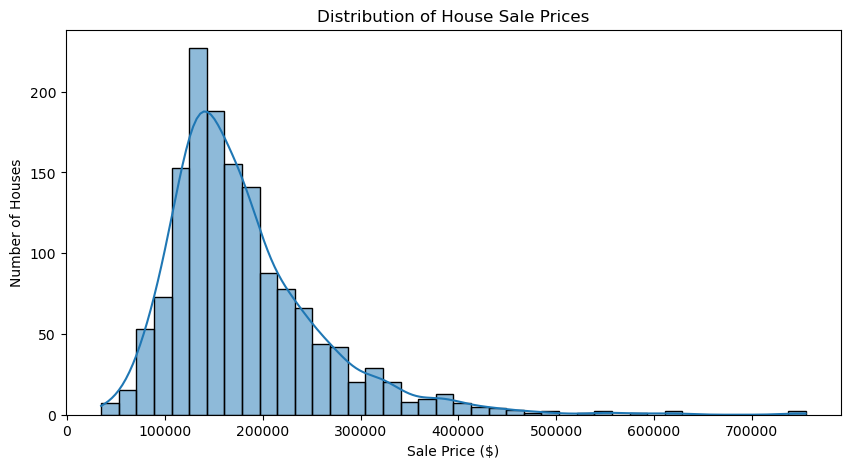

In [4]:
# Plot the distribution of house sale prices

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="SalePrice",
    bins=40,
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

In [5]:
# Calculate skewness of SalePrice

sale_price_skewness = train["SalePrice"].skew()

print("SalePrice skewness:", round(sale_price_skewness, 3))

SalePrice skewness: 1.883


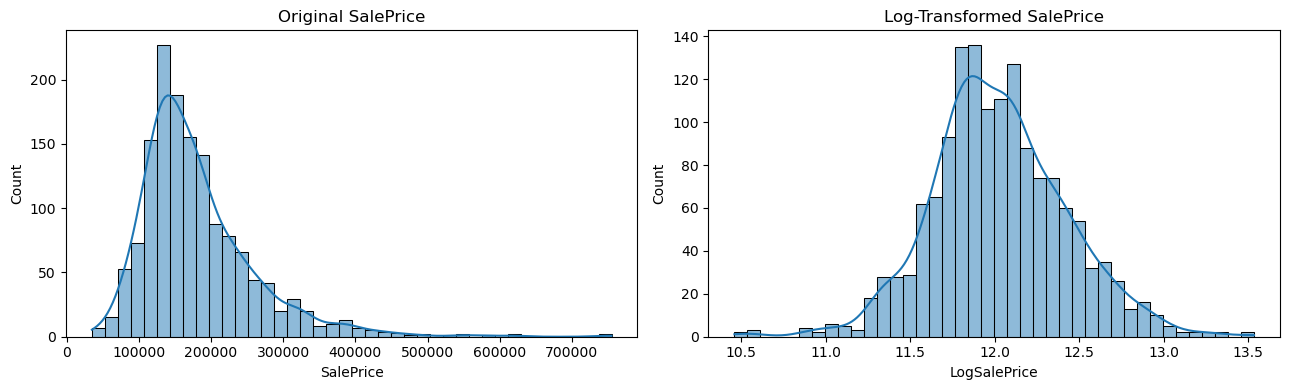

In [6]:
# Transform prices to reduce right-skewness
train["LogSalePrice"] = np.log1p(train["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(train["SalePrice"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Original SalePrice")

sns.histplot(train["LogSalePrice"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed SalePrice")

plt.tight_layout()
plt.show()

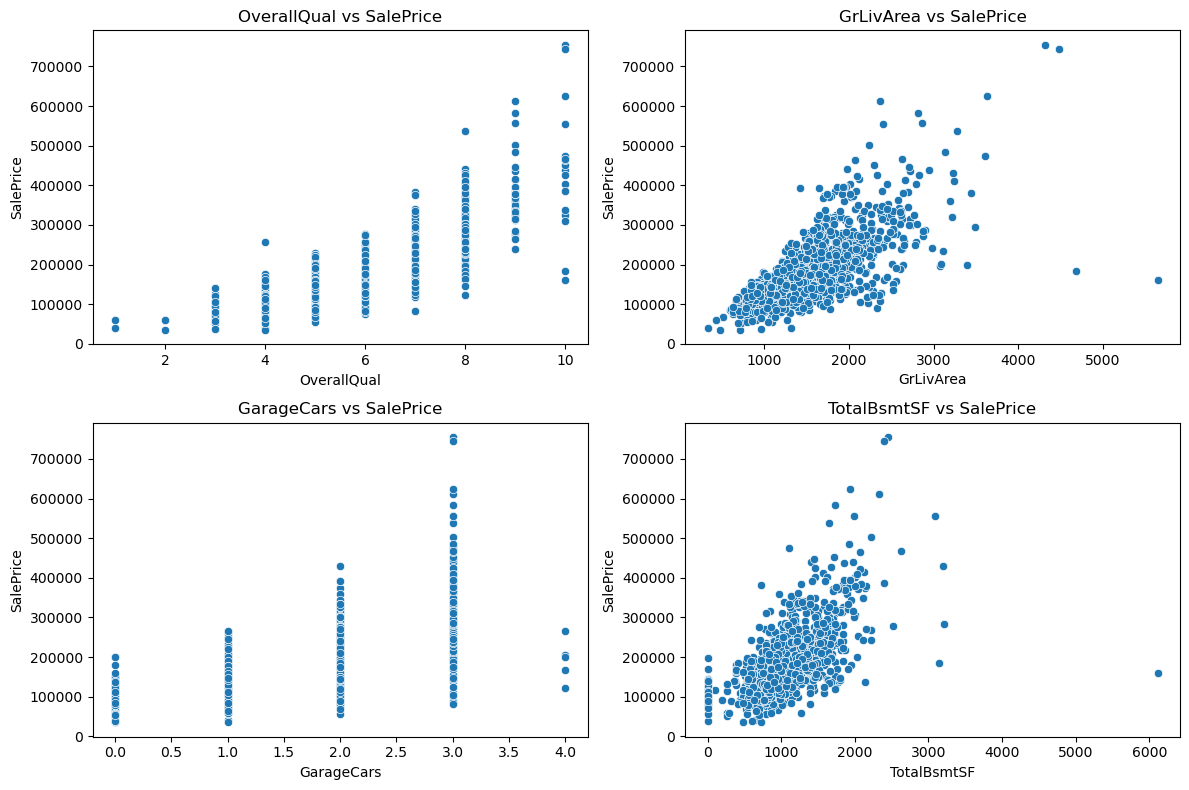

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

In [7]:
# Explore relationships between important features and SalePrice

features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(data=train, x=feature, y="SalePrice", ax=ax)
    ax.set_title(f"{feature} vs SalePrice")

plt.tight_layout()
plt.show()

# Find numerical features correlated with SalePrice
correlations = (
    train.select_dtypes(include=np.number)
    .corr()["SalePrice"]
    .drop(["SalePrice", "LogSalePrice"], errors="ignore")
    .sort_values(ascending=False)
)

display(correlations.head(10))

In [8]:
# Target: log-transformed house prices
y = np.log1p(train["SalePrice"])

# Input features: remove target and identifier
X = train.drop(columns=["SalePrice", "LogSalePrice", "Id"])

# Kaggle test data has no SalePrice column
X_test = test.drop(columns=["Id"])

print("Features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

Features: (1460, 79)
Target: (1460,)
Test features: (1459, 79)


In [9]:
# Create additional features from existing columns

def add_features(df):
    df = df.copy()

    # Total house area
    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0)
        + df["1stFlrSF"].fillna(0)
        + df["2ndFlrSF"].fillna(0)
    )

    # Total bathrooms, counting half bathrooms as 0.5
    df["TotalBathrooms"] = (
        df["FullBath"].fillna(0)
        + 0.5 * df["HalfBath"].fillna(0)
        + df["BsmtFullBath"].fillna(0)
        + 0.5 * df["BsmtHalfBath"].fillna(0)
    )

    # Age of the house when sold
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

    return df


X = add_features(X)
X_test = add_features(X_test)

print("Training features after engineering:", X.shape)
print("Test features after engineering:", X_test.shape)

Training features after engineering: (1460, 82)
Test features after engineering: (1459, 82)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

Training rows: 1168
Validation rows: 292


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(exclude=np.number).columns

# Numerical preprocessing: fill missing values and scale
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [12]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "Ridge Regression": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

results = []

for name, model in models.items():

    # Combine preprocessing and model training
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    # Predict log prices on validation data
    predictions_log = pipeline.predict(X_valid)

    # Convert prices back to dollars
    predictions = np.expm1(predictions_log)
    actual_prices = np.expm1(y_valid)

    results.append({
        "Model": name,
        "Log RMSE": np.sqrt(
            mean_squared_error(y_valid, predictions_log)
        ),
        "MAE ($)": mean_absolute_error(
            actual_prices, predictions
        ),
        "R2": r2_score(y_valid, predictions_log)
    })

results_df = pd.DataFrame(results).sort_values("Log RMSE")

display(results_df)

,Model,Log RMSE,MAE ($),R2
0,Ridge Regression,0.136486,16429.625754,0.900175
2,Extra Trees,0.142022,16447.401589,0.891913
1,Random Forest,0.145777,17335.728397,0.886122


Best model: Ridge Regression


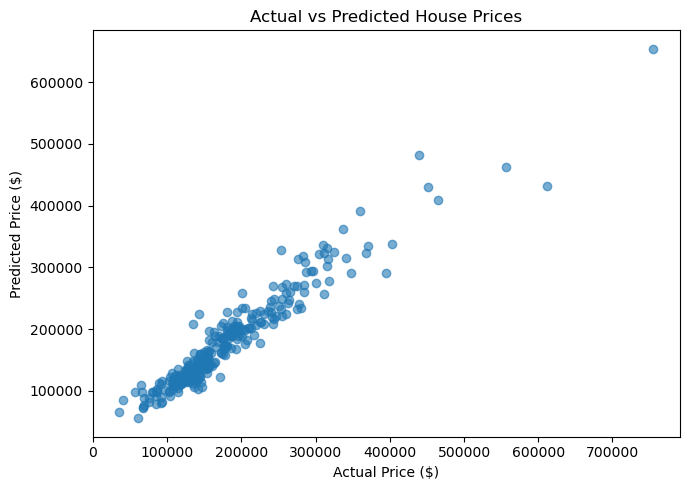

In [16]:
# Select the best model from our comparison
best_model_name = results_df.iloc[0]["Model"]

print("Best model:", best_model_name)

# Rebuild and train the selected model
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10))
])

best_model.fit(X_train, y_train)

# Predict validation prices
predictions_log = best_model.predict(X_valid)

predictions = np.expm1(predictions_log)
actual_prices = np.expm1(y_valid)

# Plot actual vs predicted prices
plt.figure(figsize=(7, 5))

plt.scatter(actual_prices, predictions, alpha=0.6)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

In [17]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(
    best_model,
    "models/best_house_price_model.joblib"
)

print("Ridge Regression model saved successfully!")

Ridge Regression model saved successfully!


In [18]:
# Predict prices for the test dataset
test_predictions = np.maximum(
    np.expm1(best_model.predict(X_test)),
    0
)

# Create the submission file
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

Path("outputs").mkdir(exist_ok=True)

submission.to_csv("outputs/submission.csv", index=False)

print("Submission created successfully!")
display(submission.head())

Submission created successfully!


,Id,SalePrice
0,1461,113474.909404
1,1462,149403.166583
2,1463,169132.777971
3,1464,189867.667961
4,1465,199491.704549


In [19]:
# Verify the submission file

print("Number of predictions:", len(submission))
print("Missing predictions:", submission["SalePrice"].isnull().sum())
print("Duplicate IDs:", submission["Id"].duplicated().sum())

print("\nSubmission summary:")
display(submission["SalePrice"].describe())

print("\nSubmission file saved at:")
print(Path("outputs/submission.csv").resolve())

Number of predictions: 1459
Missing predictions: 0
Duplicate IDs: 0

Submission summary:


count      1459.000000
mean     177946.930567
std       76609.016845
min       53340.767144
25%      126981.142241
50%      157910.598706
75%      209561.013361
max      770709.855462
Name: SalePrice, dtype: float64


Submission file saved at:
/Users/suhanimalhotra/house_price_prediction/outputs/submission.csv
